<a href="https://colab.research.google.com/github/HafizRizqi/MachineLearning_2026/blob/main/UTS/EfficientNetB0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EfficientNetB0 Grade Banana

Langkah 1 — Hubungkan Google Drive & Periksa Folder Dataset

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')
print("Google Drive berhasil dihubungkan.")

# Sesuaikan path ini dengan lokasi folder 'Real Dataset' di Google Drive Anda
folder_dataset = "/content/drive/MyDrive/Real Dataset"

print("Folder dataset ditemukan:", os.path.exists(folder_dataset))

ekstensi_gambar = (".png", ".jpg", ".jpeg", ".bmp", ".webp")

if os.path.exists(folder_dataset):
    for bagian in ["train", "validation", "test"]:
        folder_bagian = os.path.join(folder_dataset, bagian)
        print(f"\n{'=' * 15} {bagian.upper()} {'=' * 15}")
        if not os.path.isdir(folder_bagian):
            print("Folder tidak ditemukan!")
            continue
        for kelas in sorted(os.listdir(folder_bagian)):
            folder_kelas = os.path.join(folder_bagian, kelas)
            if os.path.isdir(folder_kelas):
                jumlah = sum(1 for f in os.listdir(folder_kelas) if f.lower().endswith(ekstensi_gambar))
                print(f"{kelas}: {jumlah} gambar")

Mounted at /content/drive
Google Drive berhasil dihubungkan.
Folder dataset ditemukan: True

=============== TRAIN ===============
Class A: 857 gambar
Class B: 489 gambar
Class C: 335 gambar
Class D: 415 gambar

=============== VALIDATION ===============
Class A: 286 gambar
Class B: 163 gambar
Class C: 112 gambar
Class D: 139 gambar

=============== TEST ===============
Class A: 287 gambar
Class B: 163 gambar
Class C: 112 gambar
Class D: 138 gambar


Langkah 2 — Preprocessing (Load Data, Pemetaan Grade A–D, Resize $224 \times 224$ & Augmentasi)

Found 2096 files belonging to 4 classes.
Found 700 files belonging to 4 classes.
Found 700 files belonging to 4 classes.
Pemetaan Kelas: {'Class A': 'Grade A', 'Class B': 'Grade B', 'Class C': 'Grade C', 'Class D': 'Grade D'}


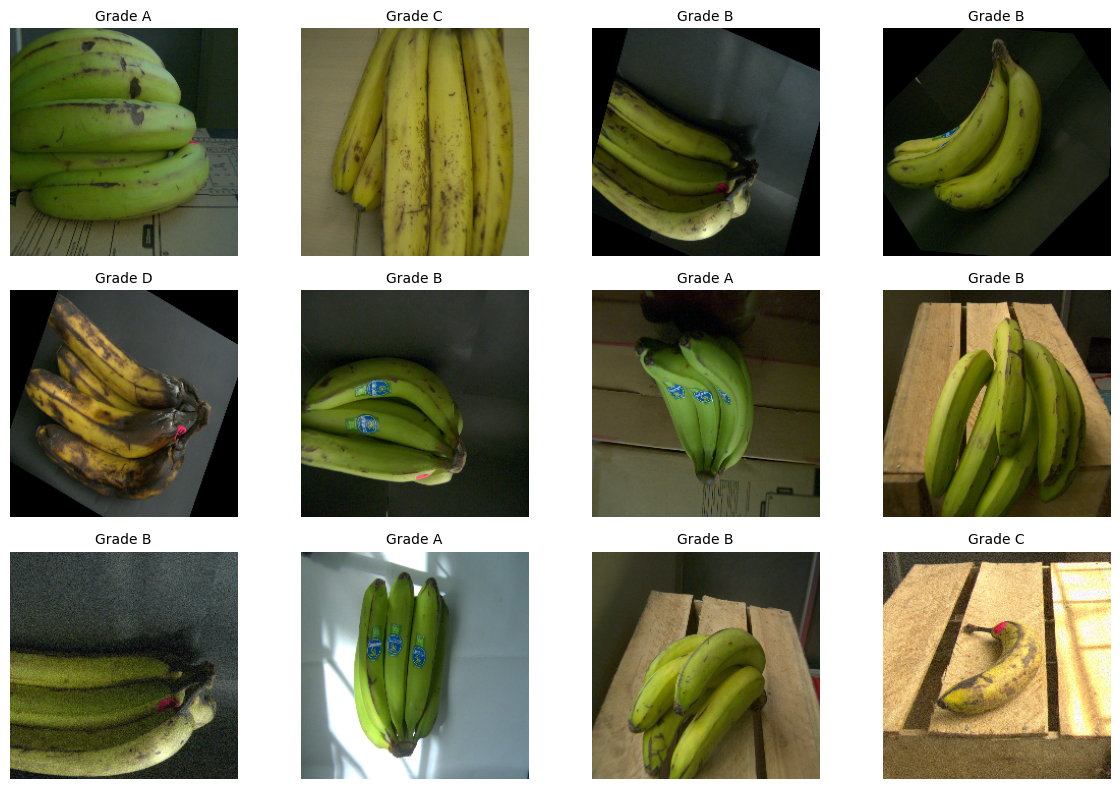

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dir = os.path.join(folder_dataset, "train")
val_dir   = os.path.join(folder_dataset, "validation")
test_dir  = os.path.join(folder_dataset, "test")

# 1. Memuat dataset dari folder train, validation, dan test
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical', shuffle=True, seed=SEED
)
val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical', shuffle=False
)
test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical', shuffle=False
)

# Pemetaan nama kelas sesuai standar SKPL & notebook kelompok
nama_grade = ["Grade A", "Grade B", "Grade C", "Grade D"]
print("Pemetaan Kelas:", dict(zip(train_ds_raw.class_names, nama_grade)))

# 2. Menampilkan 20 contoh gambar
plt.figure(figsize=(12, 8))
for images, labels in train_ds_raw.take(1):
    for i in range(min(12, len(images))):
        ax = plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        idx_kelas = np.argmax(labels[i].numpy())
        plt.title(nama_grade[idx_kelas], fontsize=10)
        plt.axis("off")
plt.tight_layout()
plt.show()

# 3. Optimasi Pipeline Data
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds_raw.cache().prefetch(buffer_size=AUTOTUNE)
val_ds   = val_ds_raw.cache().prefetch(buffer_size=AUTOTUNE)
test_ds  = test_ds_raw.cache().prefetch(buffer_size=AUTOTUNE)

# 4. Layer Data Augmentation (Simulasi variasi sudut foto & pencahayaan kamera HP sesuai UC-01)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")

Langkah 3 — Extract Feature

Menggunakan Pre-trained EfficientNetB0 sebagai pengekstraksi fitur visual pisang (warna, tekstur, bintik) dan menambahkan classifier head untuk memprediksi 4 kelas (Grade A, Grade B, Grade C, Grade D) beserta nilai confidence-nya.

In [ ]:
from tensorflow.keras import models

# 1. Memuat Base Model EfficientNetB0 (Pre-trained ImageNet)
base_model = tf.keras.applications.EfficientNetB0(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Bekukan bobot feature extractor pada tahap awal
base_model.trainable = False

# 2. Menyusun Model Lengkap
inputs = layers.Input(shape=(224, 224, 3), name="input_citra_pisang")
x = data_augmentation(inputs)

# Preprocessing internal standar EfficientNetB0
x = tf.keras.applications.efficientnet.preprocess_input(x)

# Ekstraksi fitur
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="feature_pooling")(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)

# Layer Klasifikasi Akhir (Grade A, B, C, D)
x = layers.Dense(128, activation='relu', name="dense_layer")(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(4, activation='softmax', name="output_grade")(x)

model = models.Model(inputs, outputs, name="EfficientNetB0_Banana_Grading")
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "EfficientNetB0_Banana_Grading"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_citra_pisang (InputLayer) │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ feature_pooling                 │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_layer (Dense)             │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_grade (Dense)            │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,219,175 (16.09 MB)

 Trainable params: 167,044 (652.52 KB)

 Non-trainable params: 4,052,131 (15.46 MB)

Langkah 4 — Training Strategy (Class Weighting & Callbacks)

Karena jumlah gambar di Real Dataset/train tidak seimbang (Class A: 857, Class B: 489–490, Class C: 335, Class D: 415), strategi pelatihan menggunakan Class Weights agar model tidak bias ke Grade A, serta menyimpan model berformat .keras

In [ ]:
from tensorflow.keras import callbacks

# 1. Menghitung jumlah file aktual per kelas di folder train secara otomatis
jumlah_per_kelas = []
for kelas in sorted(os.listdir(train_dir)):
    path_k = os.path.join(train_dir, kelas)
    if os.path.isdir(path_k):
        jml = sum(1 for f in os.listdir(path_k) if f.lower().endswith(ekstensi_gambar))
        jumlah_per_kelas.append(jml)

total_train = sum(jumlah_per_kelas)
class_weights = {i: total_train / (4.0 * count) for i, count in enumerate(jumlah_per_kelas)}
print("Class Weights untuk menyeimbangkan data:", class_weights)

# 2. Menyiapkan folder penyimpanan model
os.makedirs("/content/drive/MyDrive/models", exist_ok=True)
model_save_path = "/content/drive/MyDrive/models/banana_efficientnetb0_real.keras"

training_callbacks = [
    callbacks.ModelCheckpoint(
        filepath=model_save_path,
        monitor='val_accuracy',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

Class Weights untuk menyeimbangkan data: {0: 0.6114352392065344, 1: 1.0715746421267893, 2: 1.5641791044776119, 3: 1.2626506024096384}


Langkah 5 — Training Method (2-Stage Transfer Learning & Fine-Tuning)

1. Tahap 1 (Feature Extraction): Melatih head classifier saja selama 10 epoch.

2. Tahap 2 (Fine-Tuning): Membuka 20 layer teratas EfficientNetB0 dengan learning rate rendah (1e-4) selama 10 epoch agar mengenali detail visual kulit pisang secara spesifik.

In [ ]:
# --- TAHAP 1: Feature Extraction ---
print("=== MULAI TRAINING TAHAP 1 (FEATURE EXTRACTION) ===")
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

EPOCHS_1 = 10
history_1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_1,
    class_weight=class_weights,
    callbacks=training_callbacks
)

# --- TAHAP 2: Fine-Tuning ---
print("\n=== MULAI TRAINING TAHAP 2 (FINE-TUNING) ===")
base_model.trainable = True

# Bekukan semua layer kecuali 20 layer terakhir (BatchNormalization tetap dibekukan)
for layer in base_model.layers[:-20]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

EPOCHS_2 = 10
total_epochs = EPOCHS_1 + EPOCHS_2

history_2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=total_epochs,
    initial_epoch=history_1.epoch[-1] + 1,
    class_weight=class_weights,
    callbacks=training_callbacks
)

=== MULAI TRAINING TAHAP 1 (FEATURE EXTRACTION) ===
Epoch 1/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.6260 - loss: 1.1237
Epoch 1: val_accuracy improved from None to 0.83857, saving model to /content/drive/MyDrive/models/banana_efficientnetb0_real.keras

Epoch 1: finished saving model to /content/drive/MyDrive/models/banana_efficientnetb0_real.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 387s 6s/step - accuracy: 0.7252 - loss: 0.8501 - val_accuracy: 0.8386 - val_loss: 0.5124 - learning_rate: 0.0010
Epoch 2/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8089 - loss: 0.5155
Epoch 2: val_accuracy improved from 0.83857 to 0.84429, saving model to /content/drive/MyDrive/models/banana_efficientnetb0_real.keras

Epoch 2: finished saving model to /content/drive/MyDrive/models/banana_efficientnetb0_real.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 137s 2s/step - accuracy: 0.8168 - loss: 0.4969 - val_accuracy: 0.8443 - val_loss: 0.4001 - learning_rate: 0.0010
Epoch 3/10
66/66 ━━━━━━━━━━━━━━━━━━━━ 0

Langkah 6 — Hasil Evaluasi (Metrik Per Kelas & Confusion Matrix)

plot evaluasi menampilkan Metrik per kelas (data test) di sebelah kiri dan Confusion matrix di sebelah kanan


Akurasi Data Test (EfficientNetB0) : 90.86%
Loss Data Test    (EfficientNetB0) : 0.2529

22/22 ━━━━━━━━━━━━━━━━━━━━ 33s 2s/step
Classification Report (Data Test):
              precision    recall  f1-score   support

     Grade A     0.9331    0.9721    0.9522       287
     Grade B     0.8936    0.7730    0.8289       163
     Grade C     0.8347    0.9018    0.8670       112
     Grade D     0.9353    0.9420    0.9386       138

    accuracy                         0.9086       700
   macro avg     0.8992    0.8972    0.8967       700
weighted avg     0.9086    0.9086    0.9072       700



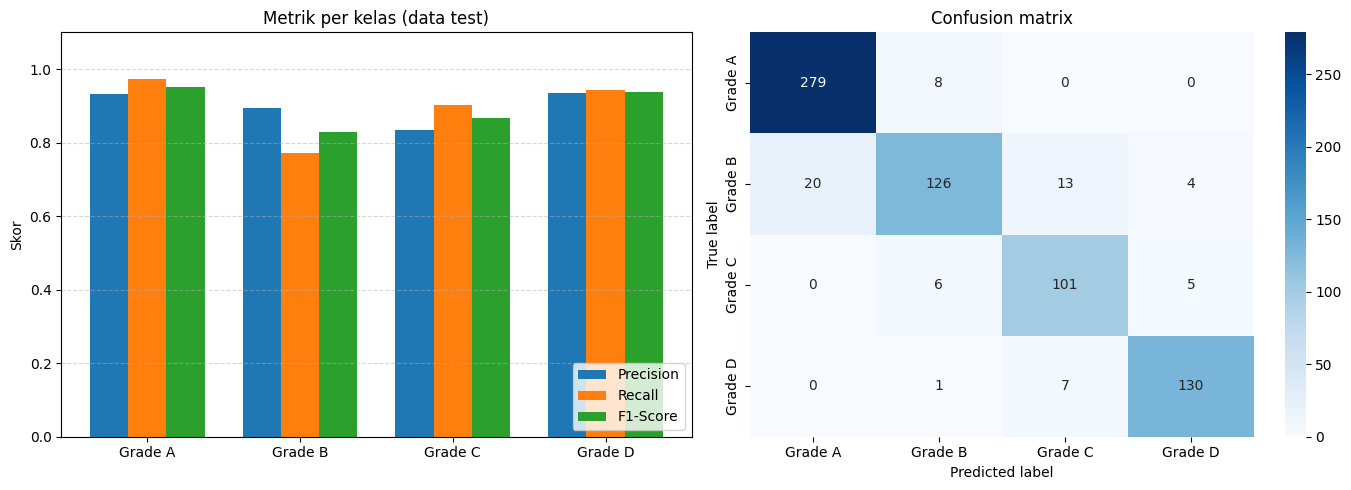

Gambar evaluasi berhasil disimpan di: /content/drive/MyDrive/models/banana_efficientnetb0_evaluation.png


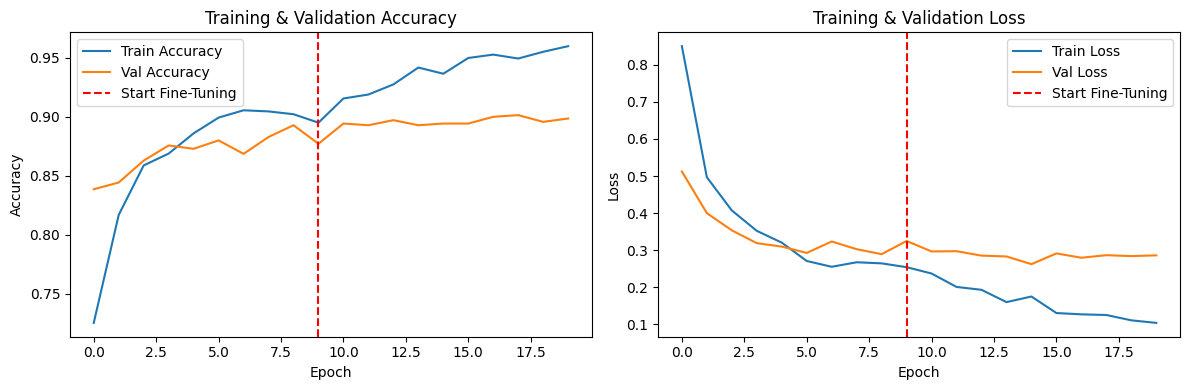

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
import seaborn as sns

# 1. Evaluasi Akurasi & Loss pada Test Set
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"\n==========================================")
print(f"Akurasi Data Test (EfficientNetB0) : {test_acc*100:.2f}%")
print(f"Loss Data Test    (EfficientNetB0) : {test_loss:.4f}")
print(f"==========================================\n")

# 2. Prediksi pada Data Test
y_pred_probs = model.predict(test_ds)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.concatenate([np.argmax(y, axis=1) for x, y in test_ds], axis=0)

# Cetak Tabel Classification Report
print("Classification Report (Data Test):")
print(classification_report(y_true, y_pred, target_names=nama_grade, digits=4))

# 3. Membuat Plot Gabungan: "Metrik per kelas (data test)" & "Confusion matrix"
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Kiri: Grafik Batang Metrik per Kelas (Precision, Recall, F1-Score)
x_pos = np.arange(len(nama_grade))
width = 0.25
axes[0].bar(x_pos - width, precision, width, label='Precision')
axes[0].bar(x_pos, recall, width, label='Recall')
axes[0].bar(x_pos + width, f1, width, label='F1-Score')
axes[0].set_title('Metrik per kelas (data test)')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(nama_grade)
axes[0].set_ylim(0, 1.1)
axes[0].set_ylabel('Skor')
axes[0].legend(loc='lower right')
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Plot Kanan: Confusion Matrix
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=nama_grade, yticklabels=nama_grade, ax=axes[1])
axes[1].set_title('Confusion matrix')
axes[1].set_xlabel('Predicted label')
axes[1].set_ylabel('True label')

plt.tight_layout()
eval_img_path = "/content/drive/MyDrive/models/banana_efficientnetb0_evaluation.png"
plt.savefig(eval_img_path, dpi=300)
plt.show()
print(f"Gambar evaluasi berhasil disimpan di: {eval_img_path}")

# 4. Plot Riwayat Training & Validation (Accuracy & Loss)
acc = history_1.history['accuracy'] + history_2.history['accuracy']
val_acc = history_1.history['val_accuracy'] + history_2.history['val_accuracy']
loss = history_1.history['loss'] + history_2.history['loss']
val_loss = history_1.history['val_loss'] + history_2.history['val_loss']

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(acc, label='Train Accuracy')
plt.plot(val_acc, label='Val Accuracy')
plt.axvline(x=len(history_1.epoch)-1, color='red', linestyle='--', label='Start Fine-Tuning')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label='Train Loss')
plt.plot(val_loss, label='Val Loss')
plt.axvline(x=len(history_1.epoch)-1, color='red', linestyle='--', label='Start Fine-Tuning')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.tight_layout()
plt.show()